Part - 2B 

Data Details:

        - Main Data Folder: SUIT_Payload_Part2
        - Data fetched from: ISSDC and GONG portal
        - Correlation Coefficients (Pearson and Spearman) calculated
        - Visualization: Correlation Coefficients resulting in Brightness Intensity v/s Magnetic Flux plot

In [1]:
# --- Imports ---------------------------------------------------------------------
import os
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import astropy.units as u
from astropy.io import fits
from astropy.time import Time
from astropy.visualization import ImageNormalize, SqrtStretch

import sunpy.map
from sunpy.coordinates import propagate_with_solar_surface
from sunpy.net import Fido
from sunpy.net import attrs as a

from scipy.stats import pearsonr, spearmanr
from skimage import filters, morphology

from skimage.filters import threshold_otsu


In [2]:
#Extracting the SUIT FITS files from the respective directory

filepath = os.path.join('./SUIT_Payload_Part2/', "*.fits")
fits_files_sorted = sorted(glob.glob(filepath))
print(f"Number of SUIT FITS files in the Dataset: {len(fits_files_sorted)}")

suit_files_maps = []
time_frame = []

for file in fits_files_sorted:
    with fits.open(file) as inFile:
        header = inFile[0].header
        obs_time = header.get('DATE-OBS', os.path.basename(file))
        print(f"File name: {file}, dated on: {obs_time}")
        suit_files_maps.append(sunpy.map.Map(file))
        time_frame.append(obs_time)

Number of SUIT FITS files in the Dataset: 7
File name: ./SUIT_Payload_Part2\SUT_T25_0588_000860_Lev1.0_2025-04-15T21.50.19.930_0973NB03.fits, dated on: 2025-04-15T21:50:19.930945000
File name: ./SUIT_Payload_Part2\SUT_T25_0588_000863_Lev1.0_2025-04-16T18.13.04.497_0973NB03.fits, dated on: 2025-04-16T18:13:04.49755000
File name: ./SUIT_Payload_Part2\SUT_T25_0589_000866_Lev1.0_2025-04-18T21.12.32.506_0973NB03.fits, dated on: 2025-04-18T21:12:32.506255000
File name: ./SUIT_Payload_Part2\SUT_T25_0589_000869_Lev1.0_2025-04-19T19.38.53.133_0973NB03.fits, dated on: 2025-04-19T19:38:53.133955000
File name: ./SUIT_Payload_Part2\SUT_T25_0589_000872_Lev1.0_2025-04-20T22.11.02.419_0973NB03.fits, dated on: 2025-04-20T22:11:02.419330000
File name: ./SUIT_Payload_Part2\SUT_T25_0589_000875_Lev1.0_2025-04-21T18.24.26.898_0973NB03.fits, dated on: 2025-04-21T18:24:26.898155000
File name: ./SUIT_Payload_Part2\SUT_T25_0589_000878_Lev1.0_2025-04-22T20.16.50.204_0973NB03.fits, dated on: 2025-04-22T20:16:50.2

In [ ]:
# Fetching the GONG Magnetogram Data

t_start = Time(time_frame[0]) - (30 * u.min)        # Explicit widening of the window size to prevent time gaps
t_end = Time(time_frame[-1]) + (30 * u.min)

result = Fido.search(a.Time(t_start, t_end), a.Instrument('GONG'))

hmi_files = sorted(Fido.fetch(result))

hmi_files_root = [sunpy.map.Map(file) for file in hmi_files]
hmi_files_time = Time([f.date for f in hmi_files_root])


Files Downloaded:   0%|          | 0/165 [00:00<?, ?file/s]

In [5]:
def suit_hmi_nearest(target_time):
    index = np.argmin(np.abs(hmi_files_time - target_time))
    return hmi_files_root[index], hmi_files_time[index]

def min_max_norm(arr_type):
    arr_type = np.array(arr_type, dtype=float)
    min = np.min(arr_type)
    max = np.max(arr_type)
    if np.abs(min - max) == 0:
        return arr_type
    else:
        return (arr_type - min)/(max - min)

arr_of_intensity = []
arr_of_field = []
arr_pearson_r = []
arr_spearman_r = []

for suit_map_file, filename in zip(suit_files_maps, fits_files_sorted):
    hmi_file, hmi_time = suit_hmi_nearest(suit_map_file.date)

    with propagate_with_solar_surface():
        hmi_on_suit = hmi_file.reproject_to(suit_map_file.wcs)

    intensity_val = np.nan_to_num(suit_map_file.data)
    field_val = np.nan_to_num(hmi_on_suit.data)

    thresh_val = threshold_otsu(intensity_val)
    mask = intensity_val > thresh_val

    intensity_samples = intensity_val[mask]
    field_samples = field_val[mask]

    intensity_norm = min_max_norm(intensity_samples)
    field_norm = min_max_norm(field_samples)

    pearson_r, _ = pearsonr(intensity_norm, field_norm)
    spearman_r, _ = spearmanr(intensity_norm, field_norm)
    arr_pearson_r.append(pearson_r)
    arr_spearman_r.append(spearman_r)

    arr_of_intensity.append(intensity_norm)
    arr_of_field.append(field_norm)

2026-08-12 23:37:19 - sunpy - INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere.


INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


2026-08-12 23:37:21 - sunpy - INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere.
2026-08-12 23:37:21 - sunpy - INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere.


INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


2026-08-12 23:37:22 - sunpy - INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere.
2026-08-12 23:37:22 - sunpy - INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere.


INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


... (6 outputs left out)

2026-08-12 23:37:28 - sunpy - INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere.
2026-08-12 23:37:28 - sunpy - INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere.


INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


2026-08-12 23:37:29 - sunpy - INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere.


INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


In [6]:
print(arr_of_intensity)

[array([9.96251726e-03, 2.42651411e-02, 2.80134149e-02, ...,
       2.08127836e-02, 2.91970803e-02, 9.86387848e-05]), array([0.00291344, 0.01127041, 0.0027601 , ..., 0.05343863, 0.02353753,
       0.01518056]), array([0.01253437, 0.00396248, 0.00137474, ..., 0.01787158, 0.0016982 ,
       0.00428595]), array([0.0002565 , 0.00461696, 0.00914843, ..., 0.04112517, 0.03924419,
       0.00820793]), array([0.00153424, 0.00169574, 0.01477713, ..., 0.00371447, 0.00137274,
       0.01122416]), array([0.02202751, 0.02399279, 0.03815919, ..., 0.00237471, 0.01138225,
       0.0208811 ]), array([0.01965772, 0.01549491, 0.01032994, ..., 0.02636448, 0.02705828,
       0.01256553])]


In [6]:
# Computing overall Pearson and Spearman Correlation Coefficients

arr_of_intensity = np.concatenate(arr_of_intensity)
arr_of_field = np.concatenate(arr_of_field)

pearson_r, pearson_p = pearsonr(arr_of_intensity, arr_of_field)
spearman_r, spearman_p = spearmanr(arr_of_intensity, arr_of_field)

print(f"Pearson r value: {pearson_r}, and Pearson p value: {pearson_p}")
print(f"Spearman r value: {spearman_r}, and Spearman p value: {spearman_p}")

Pearson r value: -0.04317526636179476, and Pearson p value: 2.0347690579837776e-224
Spearman r value: -0.008361800493747048, and Spearman p value: 5.981337294329112e-10


2026-08-12 23:46:20 - matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-08-12 23:46:20 - matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-08-12 23:46:20 - matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-08-12 23:46:20 - matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
C:\Users\kriti\AppData\Local\Temp\ipyker

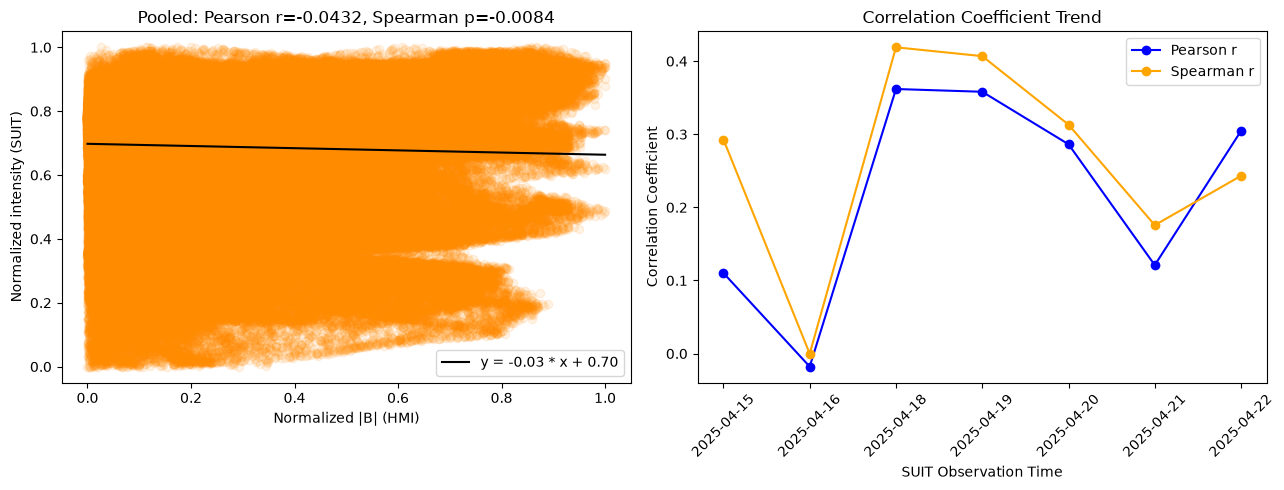

In [8]:
# Plotting

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(arr_of_intensity, arr_of_field, color="darkorange", alpha=0.1)
m, c = np.polyfit(arr_of_intensity, arr_of_field, 1)
x_val = np.linspace(0, 1, 100)
axes[0].plot(x_val, m * x_val + c, color="k", label=f"y = {m:.2f} * x + {c:.2f}")
axes[0].set_xlabel("Normalized |B| (HMI)")
axes[0].set_ylabel("Normalized intensity (SUIT)")
axes[0].set_title(f"Pooled: Pearson r={pearson_r:.4f}, Spearman p={spearman_r:.4f}")
axes[0].legend()

axes[1].plot(time_frame, arr_pearson_r, color="blue", marker="o", linestyle="-", label="Pearson r")
axes[1].plot(time_frame, arr_spearman_r, color="orange", marker="o", linestyle="-", label="Spearman r")
axes[1].set_xlabel("SUIT Observation Time")
axes[1].set_ylabel("Correlation Coefficient")
axes[1].set_title("Correlation Coefficient Trend")
axes[1].legend()

axes[1].set_xticklabels([t.split("T")[0] for t in time_frame], rotation=45)

plt.tight_layout()
plt.show()
